In [2]:
import jax
import gemlib
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import tensorflow_probability.substrates.jax as tfp
import xarray as xr
import scipy as sp

from scipy import stats
from typing import NamedTuple
from jax.typing import ArrayLike
from gemlib.deterministic import ode_model
from gemlib.distributions import DiscreteTimeStateTransitionModel
from gemlib.mcmc import hmc, rwmh, mcmc

%matplotlib inline
tfd = tfp.distributions

DTYPE=np.float32

sns.set_theme()

In [3]:
# --- Season Boundaries ---

def get_season_boundaries(start_year, n_seasons, burn_in_seasons):
    
    """
    Calculate the day boundaries of influenza seasons.
    
    Each season runs from Monday of ISO week 40 to the start of week 40 in the following year.

    Parameters:
        start_year        : Calendar year in which the first *observed* season starts.
        n_seasons         : Number of observed seasons.
        burn_in_seasons   : Number of preceding seasons simulated as burn-in.

    Returns:
        season_boundaries : Array of the season boundaries (days) since the start of the simulation.
                            Includes the initial boundary and final endpoint.
    """

    first_year = start_year - burn_in_seasons    # first year of whole simulation

    # Find Monday W40 for each season inc. final endpoint
    season_starts = [pd.Timestamp.fromisocalendar(year, 40, 1) 
                     for year in range(first_year, start_year + n_seasons + 1)]

    # Convert calendar dates into days since the first day
    season_boundaries = np.array([(date - season_starts[0]).days 
                                   for date in season_starts])

    return season_boundaries

# -----

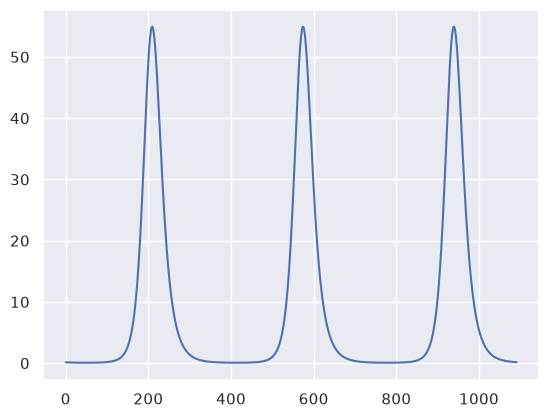

In [4]:
# --- ODE Model ---

# Incidence Matrix Setup
# - Compartments: S, E, I, R
# - Transitions: S -> E, E -> I, I -> R, R -> S
incidence_matrix = np.array([
    [-1,  0,  0,  1],  # S
    [ 1, -1,  0,  0],  # E
    [ 0,  1, -1,  0],  # I
    [ 0,  0,  1, -1]   # R
], dtype=DTYPE)

# Initial State
initial_state = np.array([[999, 0, 1, 0]], dtype=DTYPE)
popsize = 1000

# Season Boundaries
n_season = 3
n_burn_in_season = 20
season_bounds = get_season_boundaries(2012, n_season, n_burn_in_season)


def seirs_beta_t_ode_model(beta, sigma, gamma, omega, amp, phase,):    # num steps not as an argument

    def se_rate(t, state):
        seasonal_term = amp * jnp.cos(2 * np.pi * t / 365 - phase)
        beta_t = beta * jnp.exp(seasonal_term)
        return beta_t * state[:, 2] / state.sum(axis=-1)

    def ei_rate(t, state):
        return sigma
    
    def ir_rate(t, state):
        return gamma

    def rs_rate(t, state):
        return omega

    return ode_model(transition_rate_fn = [se_rate, ei_rate, ir_rate, rs_rate],
                     initial_state = initial_state,
                     incidence_matrix = incidence_matrix,
                     num_steps = season_bounds[-1],
                     initial_time = 0.0,
                     time_delta = 1.0)


# Fake Data
seirs_sim = seirs_beta_t_ode_model(beta=0.3, sigma=0.5, gamma=0.2, omega=1/180, amp=-0.2, phase=0)

times_burn = seirs_sim.times[season_bounds[n_burn_in_season]:]
states_burn = seirs_sim.states[season_bounds[n_burn_in_season]:]

sim_df = pd.DataFrame({
    "time": times_burn - season_bounds[n_burn_in_season],
    "S": states_burn[:, 0, 0],
    "E": states_burn[:, 0, 1],
    "I": states_burn[:, 0, 2],
    "R": states_burn[:, 0, 3]
})

plt.plot(sim_df["time"], sim_df["I"])

# -----

In [6]:
# --- Model Function ---

@tfd.JointDistributionCoroutineAutoBatched
def model():
    
# - Priors:
    beta = yield tfd.Normal(loc=DTYPE(0.3), scale=DTYPE(0.1), name="beta")
    sigma = 0.5
    gamma = 0.2
    omega = yield tfd.Normal(loc=DTYPE(1/180), scale=DTYPE(0.1), name="omega")
    amp = -0.2
    phase = 0

# - Model
    seirs = seirs_beta_t_ode_model(beta, sigma, gamma, omega, amp, phase)
    lmda = seirs.states[:, 0, 1] * sigma * 0.001    # sigma * E * alpha

    observation_model = yield tfd.Poisson(rate = lmda, name = "obs_cases")


pinned_model = model.experimental_pin(obs_cases=seirs_sim.states[:, 0, 2])

# -----

In [ ]:
init_pos = model.sample(seed=jax.random.key(45))

kernel = (rwmh(scale = 0.1))

samples, info = mcmc(
    num_samples=5000,
    sampling_algorithm=kernel,
    target_log_density_fn=pinned_model.log_prob,
    initial_position=init_pos,
    seed=jax.random.key(1)
)

In [ ]:
parameter_names = ["beta", "omega"]

fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

for i, ax in enumerate(axes):
    ax.plot(samples[:, i], linewidth=0.5)
    ax.set_ylabel(parameter_names[i])
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Iteration")

plt.suptitle("Traceplots - SEIRS Model")
plt.tight_layout()
plt.show()